# 0. Exploração e qualidade dos dados (EDA)
Conhecendo as tabelas, medir nulos, duplicatas, inconsistências e outliers **antes** de decidir os tratamentos posteriores. 

### 0.1 Carga dos dados e visão geral das tabelas:

In [1]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", message="numexpr")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

from pathlib import Path
RAW = Path("../data")

t = {f.stem: pd.read_csv(f) for f in sorted(RAW.glob("*.csv"))}
assert len(t) >= 9, f"Esperava 9 CSVs em {RAW.resolve()}"

visao = pd.DataFrame({
    "linhas": {k: len(v) for k, v in t.items()},
    "colunas": {k: v.shape[1] for k, v in t.items()},
    "memoria_MB": {k: round(v.memory_usage(deep=True).sum() / 1e6, 1) for k, v in t.items()},
})
display(visao)

,linhas,colunas,memoria_MB
olist_customers_dataset,99441,5,11.6
olist_geolocation_dataset,1000163,5,52.6
olist_order_items_dataset,112650,7,19.3
olist_order_payments_dataset,103886,5,8.5
olist_order_reviews_dataset,99224,7,18.7
olist_orders_dataset,99441,8,23.0
olist_products_dataset,32951,9,3.9
olist_sellers_dataset,3095,4,0.2
product_category_name_translation,71,2,0.0


**Análise:**

Analisei o tamanho e o conteúdo das tabelas do Olist e identifiquei que a geolocalização é a maior, mas não será utilizada no projeto. Também verifiquei o que cada tabela representa: pedidos, itens, pagamentos, avaliações, clientes, produtos e vendedores. Um ponto importante é que o `customer_unique_id` identifica a mesma pessoa entre diferentes compras, enquanto o `customer_id` muda a cada pedido. Com base nessa análise, defini duas tabelas fato para o modelo: uma de pedidos e outra de itens, permitindo analisar as vendas em diferentes níveis de detalhe.


### 0.2 Valores nulos por tabela e coluna:

In [2]:
linhas = []
for nome, df in t.items():
    n = df.isna().sum()
    for col, qtd in n[n > 0].items():
        linhas.append({"tabela": nome, "coluna": col, "nulos": qtd, "pct": round(100 * qtd / len(df), 2)})

nulos = pd.DataFrame(linhas).sort_values("pct", ascending=False)
display(nulos.reset_index(drop=True))
print("Tabelas sem nenhum nulo:", [k for k, v in t.items() if v.isna().sum().sum() == 0])

,tabela,coluna,nulos,pct
0,olist_order_reviews_dataset,review_comment_title,87656,88.34
1,olist_order_reviews_dataset,review_comment_message,58247,58.70
2,olist_orders_dataset,order_delivered_customer_date,2965,2.98
3,olist_products_dataset,product_category_name,610,1.85
4,olist_products_dataset,product_name_lenght,610,1.85
5,olist_products_dataset,product_description_lenght,610,1.85
6,olist_products_dataset,product_photos_qty,610,1.85
7,olist_orders_dataset,order_delivered_carrier_date,1783,1.79
8,olist_orders_dataset,order_approved_at,160,0.16
9,olist_products_dataset,product_weight_g,2,0.01


Tabelas sem nenhum nulo: ['olist_customers_dataset', 'olist_geolocation_dataset', 'olist_order_items_dataset', 'olist_order_payments_dataset', 'olist_sellers_dataset', 'product_category_name_translation']


**Análise:**

Seis das nove tabelas não têm nenhum valor nulo (clientes, geolocalização, itens, pagamentos, vendedores e tradução). Os nulos vão aparecem em três tabelas:

Nas avaliações, identifiquei muitos valores nulos nos campos de título e mensagem, mas, como são opcionais e não serão utilizados nas análises, decidi mantê-los. Na tabela de pedidos, há datas de entrega, postagem e aprovação ausentes, principalmente em pedidos não entregues ou cancelados. Por isso, mantive os valores nulos e não calculei o atraso nesses casos, evitando classificar pedidos não entregues como entregues no prazo. Já na tabela de produtos, alguns registros estão incompletos. Decidi substituir as categorias ausentes por "unknown", enquanto o peso e as dimensões foram mantidos, pois não serão utilizados no projeto.

### 0.3 Duplicatas (linhas inteiras e chaves):

In [3]:
print("Linhas totalmente duplicadas por tabela:")
display(pd.Series({k: int(v.duplicated().sum()) for k, v in t.items()}, name="duplicadas").to_frame())

chaves = {
    "orders: order_id":                       t["olist_orders_dataset"]["order_id"],
    "customers: customer_id":                 t["olist_customers_dataset"]["customer_id"],
    "products: product_id":                   t["olist_products_dataset"]["product_id"],
    "sellers: seller_id":                     t["olist_sellers_dataset"]["seller_id"],
    "reviews: order_id (esperado 1 por pedido)": t["olist_order_reviews_dataset"]["order_id"],
    "reviews: review_id":                     t["olist_order_reviews_dataset"]["review_id"],
}
display(pd.DataFrame({k: {"repetidos": int(v.duplicated().sum()), "unico?": v.is_unique} for k, v in chaves.items()}).T)

it = t["olist_order_items_dataset"]
print("items: (order_id, order_item_id) repetidos:", int(it.duplicated(["order_id", "order_item_id"]).sum()))

cu = t["olist_customers_dataset"]
print(f"customers: {cu['customer_id'].nunique()} customer_id vs {cu['customer_unique_id'].nunique()} customer_unique_id")
geo = t["olist_geolocation_dataset"]
print(f"geolocation: {len(geo)} linhas, {geo['geolocation_zip_code_prefix'].nunique()} CEPs distintos (tabela não usada no projeto)")

Linhas totalmente duplicadas por tabela:


,duplicadas
olist_customers_dataset,0
olist_geolocation_dataset,261831
olist_order_items_dataset,0
olist_order_payments_dataset,0
olist_order_reviews_dataset,0
olist_orders_dataset,0
olist_products_dataset,0
olist_sellers_dataset,0
product_category_name_translation,0


,repetidos,unico?
orders: order_id,0,True
customers: customer_id,0,True
products: product_id,0,True
sellers: seller_id,0,True
reviews: order_id (esperado 1 por pedido),551,False
reviews: review_id,814,False


items: (order_id, order_item_id) repetidos: 0
customers: 99441 customer_id vs 96096 customer_unique_id
geolocation: 1000163 linhas, 19015 CEPs distintos (tabela não usada no projeto)


**Análise:**

Verifiquei a existência de duplicatas e identifiquei que apenas a tabela de geolocalização possui linhas totalmente duplicadas. Como ela não será utilizada, não fiz alterações. Nas avaliações, encontrei pedidos e `review_id` repetidos, então defini no ETL que será mantida a avaliação mais recente de cada pedido. Também verifiquei que existem 99.441 `customer_id` para 96.096 `customer_unique_id`. Isso não é um erro, pois o mesmo cliente pode receber um novo identificador a cada compra. Por isso, utilizarei o `customer_unique_id` para identificar os clientes nas análises.


### 0.4 Consistência: status, datas, preços e pagamentos:

In [4]:
o = t["olist_orders_dataset"].copy()
for c in [c for c in o.columns if c.endswith(("_at", "_date")) or "timestamp" in c]:
    o[c] = pd.to_datetime(o[c])

print("Pedidos por status:")
display(o["order_status"].value_counts().to_frame("pedidos"))

ent = o["order_status"] == "delivered"
checks = {
    "entregue sem data de entrega ao cliente": ent & o["order_delivered_customer_date"].isna(),
    "não entregue, mas com data de entrega":   ~ent & o["order_delivered_customer_date"].notna(),
    "aprovação antes da compra":               o["order_approved_at"] < o["order_purchase_timestamp"],
    "postagem antes da aprovação":             o["order_delivered_carrier_date"] < o["order_approved_at"],
    "entrega ao cliente antes da postagem":    o["order_delivered_customer_date"] < o["order_delivered_carrier_date"],
    "entrega antes da compra":                 o["order_delivered_customer_date"] < o["order_purchase_timestamp"],
}
display(pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="pedidos").to_frame())

it = t["olist_order_items_dataset"]
pg = t["olist_order_payments_dataset"]
rv = t["olist_order_reviews_dataset"]
extra = {
    "items: price <= 0": int((it["price"] <= 0).sum()),
    "items: freight < 0": int((it["freight_value"] < 0).sum()),
    "payments: payment_value <= 0": int((pg["payment_value"] <= 0).sum()),
    "payments: tipo 'not_defined'": int((pg["payment_type"] == "not_defined").sum()),
    "payments: parcelas = 0": int((pg["payment_installments"] == 0).sum()),
    "reviews: nota fora de 1-5": int((~rv["review_score"].between(1, 5)).sum()),
}
display(pd.Series(extra, name="ocorrências").to_frame())

Pedidos por status:


,pedidos
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,pedidos
entregue sem data de entrega ao cliente,8
"não entregue, mas com data de entrega",6
aprovação antes da compra,0
postagem antes da aprovação,1359
entrega ao cliente antes da postagem,23
entrega antes da compra,0


,ocorrências
items: price <= 0,0
items: freight < 0,0
payments: payment_value <= 0,9
payments: tipo 'not_defined',3
payments: parcelas = 0,2
reviews: nota fora de 1-5,0


**Análise:**

Analisei os pedidos e identifiquei que 97% foram entregues. Os pedidos cancelados ou indisponíveis foram excluídos do modelo, enquanto os demais status foram mantidos como pedidos em andamento. Também verifiquei algumas inconsistências nas datas, mas decidi mantê-las, pois não afetam o cálculo do prazo de entrega. Os oito pedidos entregues sem data de entrega ficaram fora do cálculo de atraso. Nos itens e nas avaliações, não encontrei valores inválidos de preço, frete ou nota. Já nos pagamentos, encontrei poucos registros inconsistentes, que foram mantidos por não afetarem o cálculo da receita, baseado no preço dos itens.

### 0.5 Outliers: prazo de entrega, preço, frete e peso:

In [5]:
o["delivery_days"] = (o["order_delivered_customer_date"] - o["order_purchase_timestamp"]).dt.days
prod = t["olist_products_dataset"]

variaveis = {
    "delivery_days": o["delivery_days"].dropna(),
    "price": it["price"],
    "freight_value": it["freight_value"],
    "product_weight_g": prod["product_weight_g"].dropna(),
}

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    lim = q3 + 1.5 * (q3 - q1)
    return int((s > lim).sum()), round(lim, 1)

resumo = pd.DataFrame({k: v.describe(percentiles=[.5, .95, .99]) for k, v in variaveis.items()}).T.round(1)
resumo["acima_do_limite_IQR"] = [iqr_outliers(v)[0] for v in variaveis.values()]
resumo["limite_IQR"] = [iqr_outliers(v)[1] for v in variaveis.values()]
display(resumo)

dados = {"Dias até a entrega": variaveis["delivery_days"],
         "Preço do item (R$)": variaveis["price"],
         "Frete (R$)": variaveis["freight_value"],
         "Peso do produto (g)": variaveis["product_weight_g"]}

,count,mean,std,min,50%,95%,99%,max,acima_do_limite_IQR,limite_IQR
delivery_days,96476.0,12.1,9.6,0.0,10.0,29.0,46.0,209.0,5025,28.5
price,112650.0,120.7,183.6,0.8,75.0,349.9,890.0,6735.0,8427,277.4
freight_value,112650.0,20.0,15.8,0.0,16.3,45.1,84.5,409.7,11613,33.3
product_weight_g,32949.0,2276.5,4282.0,0.0,700.0,10850.0,22538.0,40425.0,4551,4300.0


Valores iguais a zero: {'Dias até a entrega': 13, 'Preço do item (R$)': 0, 'Frete (R$)': 383, 'Peso do produto (g)': 4}
Entregas com mais de 60 dias: 288


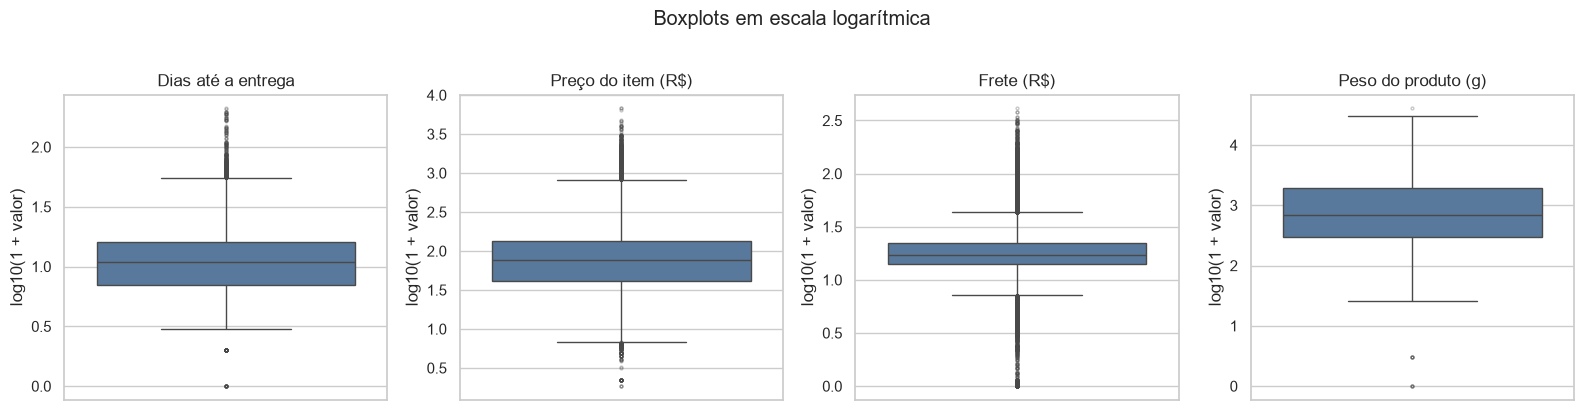

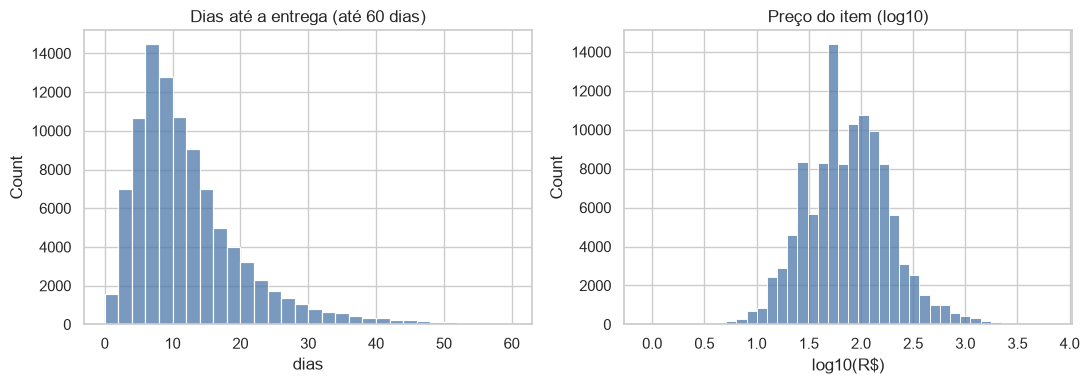

In [6]:
print("Valores iguais a zero:", {k: int((v == 0).sum()) for k, v in dados.items()})
print("Entregas com mais de 60 dias:", int((dados["Dias até a entrega"] > 60).sum()))

# Boxplots em escala log: os dados são muito assimétricos e, na escala original,
# a caixa fica espremida e milhares de pontos aparecem como "outliers"
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (nome, s) in zip(ax, dados.items()):
    sns.boxplot(y=np.log10(s + 1), ax=a, color="#4C78A8", flierprops=dict(markersize=2, alpha=0.3))
    a.set(title=nome, ylabel="log10(1 + valor)")
plt.suptitle("Boxplots em escala logarítmica", y=1.02)
plt.tight_layout(); plt.show()

# Histogramas: prazo sem cortar a cauda (apenas até 60 dias) e preço em log10
prazo = dados["Dias até a entrega"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(prazo[prazo <= 60], bins=30, ax=ax[0], color="#4C78A8")
ax[0].set(title="Dias até a entrega (até 60 dias)", xlabel="dias")
sns.histplot(np.log10(dados["Preço do item (R$)"]), bins=40, ax=ax[1], color="#4C78A8")
ax[1].set(title="Preço do item (log10)", xlabel="log10(R$)")
plt.tight_layout(); plt.show()

**Análise:**

Ao analisar os valores extremos, percebi que o boxplot original do frete não apresentava uma boa visualização, pois os dados são muito assimétricos, com uma cauda longa à direita. Por isso, refiz os boxplots utilizando escala logarítmica. Também ajustei o histograma do prazo de entrega para mostrar os valores até 60 dias, evitando que as entregas mais longas ficassem agrupadas incorretamente em uma única barra.

O critério IQR identificou muitos possíveis outliers: 5.025 prazos de entrega, 8.427 preços, 11.613 valores de frete e 4.551 pesos. No entanto, esses percentuais são altos e não significam necessariamente que os dados estejam errados, já que as distribuições são assimétricas.

Também analisei os valores extremos e encontrei prazos de entrega de até 209 dias, preços de produtos de até R$ 6.735, fretes iguais a zero e produtos com peso de até 40,4 kg. Apesar de alguns casos serem raros, eles podem acontecer na prática. Identifiquei ainda quatro produtos com peso igual a zero, mas essa variável não será utilizada nas análises.

Diante disso, decidi não remover os valores extremos, pois eles podem representar situações reais do negócio. Como os dados apresentam distribuições assimétricas, utilizarei a mediana em vez da média e testes não paramétricos nas análises.

### 0.6 Distribuição e normalidade das variáveis numéricas:

,assimetria,curtose,assimetria (log),curtose (log),Shapiro p,Shapiro p (log)
variável,,,,,,
Dias até a entrega,3.83,39.26,-0.08,0.24,7.4e-60,1.8e-14
Preço do item (R$),7.92,120.83,0.29,0.45,2.8e-83,1.0e-16
Frete (R$),5.64,59.79,0.00,5.22,1.5e-75,5.1e-46
Peso do produto (g),3.60,15.13,0.47,-0.19,4.3e-79,1.3e-30


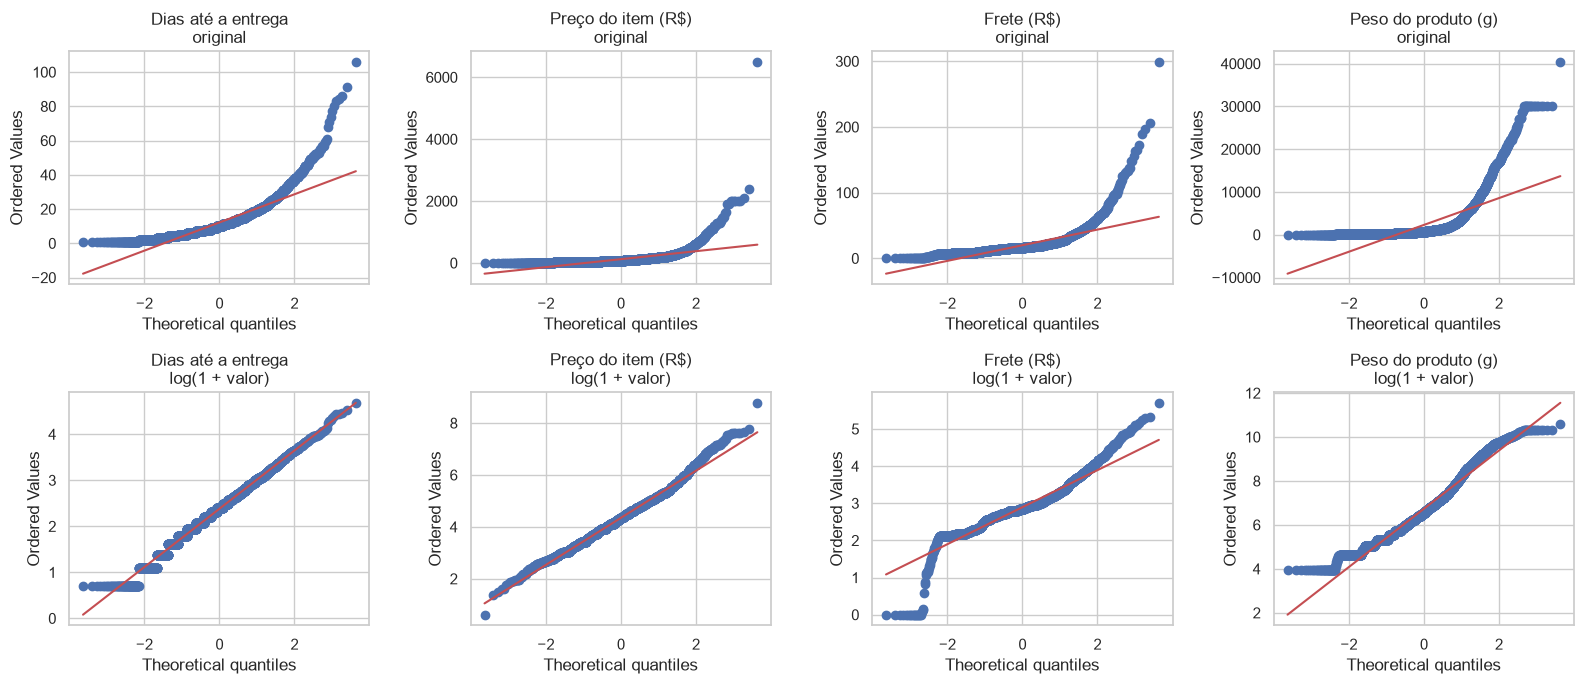

In [7]:
from scipy import stats

rng = np.random.default_rng(42)
amostras = {nome: rng.choice(s.to_numpy(), size=5000, replace=False) for nome, s in dados.items()}

linhas = []
for nome, s in dados.items():
    a = amostras[nome]
    p_orig = stats.shapiro(a).pvalue
    p_log = stats.shapiro(np.log1p(a)).pvalue
    linhas.append({"variável": nome,
                   "assimetria": s.skew(), "curtose": s.kurt(),
                   "assimetria (log)": np.log1p(s).skew(), "curtose (log)": np.log1p(s).kurt(),
                   "Shapiro p": f"{p_orig:.1e}", "Shapiro p (log)": f"{p_log:.1e}"})
display(pd.DataFrame(linhas).set_index("variável").round(2))

fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for j, (nome, a) in enumerate(amostras.items()):
    stats.probplot(a, dist="norm", plot=ax[0, j]);          ax[0, j].set_title(f"{nome}\noriginal")
    stats.probplot(np.log1p(a), dist="norm", plot=ax[1, j]); ax[1, j].set_title(f"{nome}\nlog(1 + valor)")
plt.tight_layout(); plt.show()

**Análise:**

Analisei a distribuição das variáveis e percebi que, na escala original, todas apresentam forte assimetria à direita, principalmente o preço e o frete. Isso também aparece na diferença entre a média e a mediana, além dos desvios nos gráficos Q-Q. Por isso, apliquei a transformação logarítmica, que reduziu bastante a assimetria e deixou as distribuições mais próximas de uma forma simétrica.

Mesmo após a transformação, o teste de Shapiro-Wilk rejeitou a normalidade de todas as variáveis. Porém, como foram utilizadas 5.000 observações, o teste pode identificar até pequenos desvios. Assim, considerei também os gráficos Q-Q e os valores de assimetria para avaliar o comportamento dos dados.

Com base nesses resultados, decidi utilizar métodos estatísticos que não dependem da normalidade, como mediana, Mann-Whitney, Kruskal-Wallis, correlação de Spearman e bootstrap para calcular intervalos de confiança. Dessa forma, as análises ficam mais adequadas às características dos dados.

### 0.7 Cobertura temporal: meses com poucos pedidos:

ano_mes,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
pedidos,4,324,1,800,1780,2682,2404,3700,3245,4026,4331,4285,4631,7544,5673,7269,6728,7211,6939,6873,6167,6292,6512,16,4


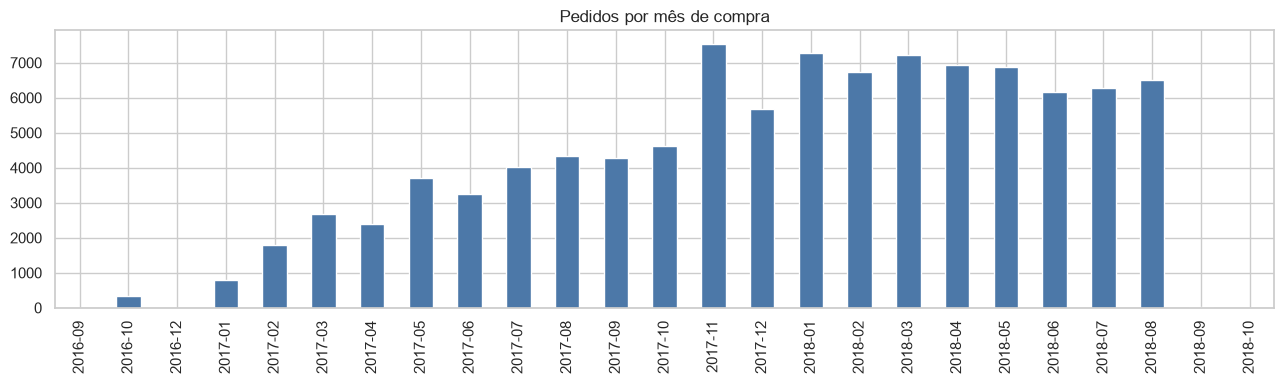

Primeiro pedido: 2016-09-04 21:15:19
Último pedido:   2018-10-17 17:30:18
Meses com menos de 500 pedidos: ['2016-09', '2016-10', '2016-12', '2018-09', '2018-10']


In [8]:
mes = (o.assign(ano_mes=o["order_purchase_timestamp"].dt.to_period("M").astype(str))
         .groupby("ano_mes").size().rename("pedidos"))
display(mes.to_frame().T)

mes.plot(kind="bar", figsize=(13, 4), color="#4C78A8", title="Pedidos por mês de compra")
plt.xlabel(""); plt.tight_layout(); plt.show()

print("Primeiro pedido:", o["order_purchase_timestamp"].min())
print("Último pedido:  ", o["order_purchase_timestamp"].max())
print("Meses com menos de 500 pedidos:", list(mes[mes < 500].index))

**Análise:**

Ao analisar a evolução mensal dos pedidos, identifiquei meses com volumes muito baixos, principalmente no início e no final da base. O volume cresce ao longo de 2017, atingindo o pico de 7.544 pedidos em novembro, mês da Black Friday, e se mantém relativamente estável entre janeiro e agosto de 2018.

Essas variações podem distorcer a análise de crescimento mensal, especialmente nos períodos com poucos pedidos e durante a expansão inicial da plataforma. Por isso, decidi restringir essa análise ao período de janeiro de 2017 a agosto de 2018, que possui 20 meses completos. As análises de atraso e avaliação podem utilizar um período maior, pois não dependem diretamente do volume mensal de pedidos.

### 0.8 Categorias de produto sem tradução e produtos sem categoria:

In [9]:
trad = t["product_category_name_translation"]
sem_trad = (prod.loc[prod["product_category_name"].notna()
                     & ~prod["product_category_name"].isin(trad["product_category_name"]),
                     "product_category_name"].value_counts())
print("Categorias sem tradução:")
display(sem_trad.to_frame("produtos"))
print("Produtos sem categoria (nulo):", int(prod["product_category_name"].isna().sum()), "de", len(prod))

vend = (it.merge(prod[["product_id", "product_category_name"]], on="product_id", how="left"))
print(f"Itens vendidos sem categoria: {vend['product_category_name'].isna().mean():.2%}")

Categorias sem tradução:


,produtos
product_category_name,
portateis_cozinha_e_preparadores_de_alimentos,10
pc_gamer,3


Produtos sem categoria (nulo): 610 de 32951
Itens vendidos sem categoria: 1.42%


**Análise:**

Na análise das categorias, identifiquei duas que não possuem tradução na tabela auxiliar, além de 610 produtos sem categoria definida. Esses produtos representam apenas 1,42% dos itens vendidos, então o impacto nas análises é pequeno. Decidi manter os nomes originais das categorias sem tradução e classificar os produtos sem categoria como "unknown", evitando perder a receita desses itens. Caso a análise por categoria se torne mais importante no relatório, posso traduzir manualmente as duas categorias que faltam.

### 0.9 Resumo das decisões de tratamento:

| Problema | Onde | Quantidade | Decisão | Justificativa |
|---|---|---|---|---|
| Comentários de avaliação nulos | reviews | 88,34% (título) e 58,70% (mensagem) | Manter | Campo opcional; não usado nas análises |
| Data de entrega nula | orders | 2.965 (2,98%) | Manter nulo; atraso também nulo | Pedido não entregue não é "no prazo" |
| Entregue sem data de entrega | orders | 8 | Manter, fora do cálculo de atraso | Volume desprezível |
| Produtos sem categoria | products | 610 (1,85%); 1,42% dos itens | Usar "unknown" | Preservar a receita desses itens |
| Categorias sem tradução | products | 2 categorias (13 produtos) | Manter o nome em português | Impacto mínimo |
| Várias avaliações por pedido | reviews | 551 pedidos repetidos | Manter a mais recente | Uma nota por pedido |
| Geolocalização duplicada | geolocation | 261.831 linhas | Tabela não usada (se usar, agregar por CEP) | Fora do escopo |
| Cancelados e indisponíveis | orders | 1.234 (1,24%) | Excluir do modelo | Sem receita realizada |
| Postagem antes da aprovação | orders | 1.359 (1,4%) | Manter | Não afeta as métricas (prazo = compra a entrega) |
| Entrega antes da postagem | orders | 23 | Manter | Idem |
| Pagamento ≤ 0, `not_defined`, 0 parcelas | payments | 9, 3 e 2 | Manter | Receita calculada pelos itens |
| Valores extremos (prazo, preço, frete, peso) | várias | IQR: 5,2%, 7,5%, 10,3% e 13,8% | Manter | Plausíveis; usar mediana e testes não paramétricos |
| Peso igual a 0 g | products | 4 produtos | Manter (não usado) | Peso não entra nas análises |
| Meses incompletos | orders | 5 meses com menos de 500 pedidos | Restringir o crescimento mensal a 2017-01 a 2018-08 | Evitar variações mês a mês distorcidas |